# Phase 1 — Dataset Exploration

**Project:** Gait-Based Biometric Authentication using DTW & Adaptive Template Updating  
**Dataset:** 200GaitData (smartphone-based gait recordings)  

---

### What this notebook does

1. Inspects the folder structure and discovers all CSV files.  
2. Loads the data and displays columns, data types, and first rows.  
3. Identifies available sensor measurements.  
4. Checks record counts, missing values, duplicates, and invalid values.  
5. Examines timestamps and estimates sampling frequency.  
6. Visualises sensor signals for several recordings.  
7. Compares participants and sessions.

> **Important:** This notebook never modifies the original CSV files.

## 0 — Setup

In [1]:
# ── Standard library ──
import os
import sys
import warnings

# ── Third-party libraries ──
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ── Project modules ──
# Add project root to sys.path so we can import from src/
PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), ".."))
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

from src.data_loader import (
    discover_csv_files,
    get_file_inventory,
    load_single_recording,
    load_all_recordings,
    check_data_quality,
    estimate_sampling_frequency,
    parse_filename,
)

# ── Plot settings ──
sns.set_theme(style="whitegrid", font_scale=1.1)
plt.rcParams["figure.figsize"] = (14, 5)
plt.rcParams["figure.dpi"] = 100
warnings.filterwarnings("ignore", category=FutureWarning)

# ── Results directory ──
RESULTS_DIR = os.path.join(PROJECT_ROOT, "results")
os.makedirs(RESULTS_DIR, exist_ok=True)

print(f"Project root : {PROJECT_ROOT}")
print(f"Results dir  : {RESULTS_DIR}")
print("Setup complete ✓")

Project root : /Users/prathameshpatil/Desktop/gait-auth
Results dir  : /Users/prathameshpatil/Desktop/gait-auth/results
Setup complete ✓


---
## 1 — Folder Structure & File Discovery

In [2]:
# 1a. Walk the project tree (only files, skip hidden/system files)
print("Project folder structure:\n")
for root, dirs, files in os.walk(PROJECT_ROOT):
    # Skip hidden directories like .git, .DS_Store, __pycache__
    dirs[:] = [d for d in dirs if not d.startswith(".") and d != "__pycache__"]
    level = root.replace(PROJECT_ROOT, "").count(os.sep)
    indent = "  " * level
    folder_name = os.path.basename(root)
    print(f"{indent}📁 {folder_name}/")
    sub_indent = "  " * (level + 1)
    for f in sorted(files):
        if not f.startswith("."):
            print(f"{sub_indent}📄 {f}")

Project folder structure:

📁 gait-auth/
  📄 requirements.txt
  📁 results/
  📁 data/
    📁 raw/
      📄  sub1-rp-s1.csv
      📄  sub1-rp-s2.csv
      📄  sub10-rp-s1.csv
      📄  sub10-rp-s2.csv
      📄  sub13-rp-s1.csv
      📄  sub13-rp-s2.csv
      📄  sub14-rp-s1.csv
      📄  sub14-rp-s2.csv
      📄  sub15-rp-s1.csv
      📄  sub15-rp-s2.csv
      📄  sub16-rp-s1.csv
      📄  sub16-rp-s2.csv
      📄  sub18-rp-s1.csv
      📄  sub18-rp-s2.csv.csv
      📄  sub2-rp-s1.csv
      📄  sub2-rp-s2.csv
      📄  sub3-rp-s1.csv
      📄  sub3-rp-s2.csv
      📄  sub4-rp-s1.csv
      📄  sub4-rp-s2.csv.csv
  📁 notebooks/
    📄 dataset_exploration.ipynb
  📁 src/
    📄 __init__.py
    📄 data_loader.py


In [3]:
# 1b. Discover all CSV files and their naming conventions
csv_files = discover_csv_files()
print(f"Total CSV files found: {len(csv_files)}\n")

for i, fp in enumerate(csv_files, 1):
    fname = os.path.basename(fp)
    print(f"  {i:2d}. {fname!r}")

print("\n--- Naming convention ---")
print("Pattern: ' sub<PARTICIPANT_ID>-rp-s<SESSION>.csv'")
print("Notes:")
print("  • Filenames have a leading space.")
print("  • Some files have a double .csv.csv extension.")
print("  • 'rp' likely stands for 'right pocket' (phone placement).")

Total CSV files found: 20

   1. ' sub1-rp-s1.csv'
   2. ' sub1-rp-s2.csv'
   3. ' sub10-rp-s1.csv'
   4. ' sub10-rp-s2.csv'
   5. ' sub13-rp-s1.csv'
   6. ' sub13-rp-s2.csv'
   7. ' sub14-rp-s1.csv'
   8. ' sub14-rp-s2.csv'
   9. ' sub15-rp-s1.csv'
  10. ' sub15-rp-s2.csv'
  11. ' sub16-rp-s1.csv'
  12. ' sub16-rp-s2.csv'
  13. ' sub18-rp-s1.csv'
  14. ' sub18-rp-s2.csv.csv'
  15. ' sub2-rp-s1.csv'
  16. ' sub2-rp-s2.csv'
  17. ' sub3-rp-s1.csv'
  18. ' sub3-rp-s2.csv'
  19. ' sub4-rp-s1.csv'
  20. ' sub4-rp-s2.csv.csv'

--- Naming convention ---
Pattern: ' sub<PARTICIPANT_ID>-rp-s<SESSION>.csv'
Notes:
  • Filenames have a leading space.
  • Some files have a double .csv.csv extension.
  • 'rp' likely stands for 'right pocket' (phone placement).


In [4]:
# 1c. File inventory with parsed metadata
inventory = get_file_inventory()
print("File inventory:\n")
display(inventory)

File inventory:



,participant_id,session,filename,filepath,file_size_bytes
0,1,1,sub1-rp-s1.csv,/Users/prathameshpatil/Desktop/gait-auth/data/...,3971558
1,1,2,sub1-rp-s2.csv,/Users/prathameshpatil/Desktop/gait-auth/data/...,3789209
2,2,1,sub2-rp-s1.csv,/Users/prathameshpatil/Desktop/gait-auth/data/...,4065525
3,2,2,sub2-rp-s2.csv,/Users/prathameshpatil/Desktop/gait-auth/data/...,3869177
4,3,1,sub3-rp-s1.csv,/Users/prathameshpatil/Desktop/gait-auth/data/...,3731272
5,3,2,sub3-rp-s2.csv,/Users/prathameshpatil/Desktop/gait-auth/data/...,3927294
6,4,1,sub4-rp-s1.csv,/Users/prathameshpatil/Desktop/gait-auth/data/...,2568951
7,4,2,sub4-rp-s2.csv.csv,/Users/prathameshpatil/Desktop/gait-auth/data/...,4157837
8,10,1,sub10-rp-s1.csv,/Users/prathameshpatil/Desktop/gait-auth/data/...,4549910
9,10,2,sub10-rp-s2.csv,/Users/prathameshpatil/Desktop/gait-auth/data/...,4233171


---
## 2 — Load & Inspect the Data

In [5]:
# 2a. Load all recordings at once
recordings = load_all_recordings()
print(f"Loaded {len(recordings)} recordings.\n")
print("Keys:", list(recordings.keys()))

Loaded 20 recordings.

Keys: ['sub1-rp-s1', 'sub1-rp-s2', 'sub10-rp-s1', 'sub10-rp-s2', 'sub13-rp-s1', 'sub13-rp-s2', 'sub14-rp-s1', 'sub14-rp-s2', 'sub15-rp-s1', 'sub15-rp-s2', 'sub16-rp-s1', 'sub16-rp-s2', 'sub18-rp-s1', 'sub18-rp-s2', 'sub2-rp-s1', 'sub2-rp-s2', 'sub3-rp-s1', 'sub3-rp-s2', 'sub4-rp-s1', 'sub4-rp-s2']


In [6]:
# 2b. Display columns and first 10 rows for each recording
for name, df in sorted(recordings.items()):
    print(f"\n{'='*60}")
    print(f"Recording: {name}")
    print(f"Columns  : {list(df.columns)}")
    print(f"Dtypes   : {df.dtypes.to_dict()}")
    print(f"Shape    : {df.shape}")
    print(f"{'='*60}")
    display(df.head(10))
    print()


Recording: sub1-rp-s1
Columns  : ['OriginalIndex', 'Timestamp', 'X', 'Y', 'Z', 'Label']
Dtypes   : {'OriginalIndex': dtype('int64'), 'Timestamp': dtype('float64'), 'X': dtype('float64'), 'Y': dtype('float64'), 'Z': dtype('float64'), 'Label': dtype('O')}
Shape    : (48000, 6)


,OriginalIndex,Timestamp,X,Y,Z,Label
0,2001,271130.701828,-0.241165,-0.548370,-0.086136,G
1,2002,271130.711777,-0.238922,-0.522552,-0.057205,G
2,2003,271130.721756,-0.238739,-0.518753,-0.025604,G
3,2004,271130.731735,-0.248627,-0.534775,0.016464,G
4,2005,271130.741684,-0.265549,-0.568924,0.053650,G
5,2006,271130.751663,-0.287949,-0.606232,0.088150,G
6,2007,271130.761642,-0.322693,-0.665268,0.139008,G
7,2008,271130.771622,-0.352310,-0.721359,0.184906,G
8,2009,271130.781570,-0.375290,-0.760254,0.157501,G
9,2010,271130.791550,-0.416824,-0.807373,0.077087,G




Recording: sub1-rp-s2
Columns  : ['OriginalIndex', 'Timestamp', 'X', 'Y', 'Z', 'Label']
Dtypes   : {'OriginalIndex': dtype('int64'), 'Timestamp': dtype('float64'), 'X': dtype('float64'), 'Y': dtype('float64'), 'Z': dtype('float64'), 'Label': dtype('O')}
Shape    : (46000, 6)


,OriginalIndex,Timestamp,X,Y,Z,Label
0,2001,13167.578129,-0.001831,-1.003189,0.008957,G
1,2002,13167.588108,-0.012970,-1.010330,0.005188,G
2,2003,13167.598087,-0.018417,-1.006622,0.005600,G
3,2004,13167.608067,-0.013412,-1.002823,0.015366,G
4,2005,13167.618046,-0.006042,-1.001633,0.023331,G
5,2006,13167.627995,0.005081,-1.003372,0.028793,G
6,2007,13167.637974,0.008972,-1.002792,0.033325,G
7,2008,13167.647953,0.021011,-1.002548,0.013229,G
8,2009,13167.657932,0.033081,-1.002716,-0.009186,G
9,2010,13167.667912,0.033310,-1.007202,-0.031586,G




Recording: sub10-rp-s1
Columns  : ['OriginalIndex', 'Timestamp', 'X', 'Y', 'Z', 'Label']
Dtypes   : {'OriginalIndex': dtype('int64'), 'Timestamp': dtype('float64'), 'X': dtype('float64'), 'Y': dtype('float64'), 'Z': dtype('float64'), 'Label': dtype('O')}
Shape    : (56000, 6)


,OriginalIndex,Timestamp,X,Y,Z,Label
0,2001,8951.636657,0.293533,-0.690598,0.014084,G
1,2002,8951.646606,0.273987,-0.728333,0.051498,G
2,2003,8951.656585,0.250214,-0.798599,-0.016693,G
3,2004,8951.666534,0.213715,-0.893616,-0.370010,G
4,2005,8951.676513,0.204102,-0.917267,-0.703049,G
5,2006,8951.686492,0.175827,-1.019791,-0.576935,G
6,2007,8951.696441,0.162903,-0.984512,-0.301437,G
7,2008,8951.706420,0.169861,-0.959549,-0.121643,G
8,2009,8951.716369,0.176834,-1.003006,-0.016861,G
9,2010,8951.726348,0.186172,-1.071732,0.079742,G


... (30 outputs left out)



Recording: sub4-rp-s1
Columns  : ['OriginalIndex', 'Timestamp', 'X', 'Y', 'Z', 'Label']
Dtypes   : {'OriginalIndex': dtype('int64'), 'Timestamp': dtype('float64'), 'X': dtype('float64'), 'Y': dtype('float64'), 'Z': dtype('float64'), 'Label': dtype('O')}
Shape    : (31000, 6)


,OriginalIndex,Timestamp,X,Y,Z,Label
0,8001,278463.585798,-0.089142,-1.051208,0.041809,G
1,8002,278463.595748,-0.070312,-1.038254,0.045166,G
2,8003,278463.605652,-0.050003,-1.039902,0.056686,G
3,8004,278463.615601,-0.036850,-1.052933,0.071518,G
4,8005,278463.625550,-0.025650,-1.058350,0.091049,G
5,8006,278463.635529,-0.016449,-1.055740,0.105606,G
6,8007,278463.645478,-0.007416,-1.043320,0.118484,G
7,8008,278463.655427,-0.003113,-1.028152,0.129211,G
8,8009,278463.665375,0.000748,-1.040543,0.140350,G
9,8010,278463.675324,-0.000290,-1.116150,0.162949,G




Recording: sub4-rp-s2
Columns  : ['OriginalIndex', 'Timestamp', 'X', 'Y', 'Z', 'Label']
Dtypes   : {'OriginalIndex': dtype('int64'), 'Timestamp': dtype('float64'), 'X': dtype('float64'), 'Y': dtype('float64'), 'Z': dtype('float64'), 'Label': dtype('O')}
Shape    : (50000, 6)


,OriginalIndex,Timestamp,X,Y,Z,Label
0,2001,125328.923649,-0.034225,-0.834457,-0.160141,G
1,2002,125328.933659,-0.030533,-0.714279,-0.170288,G
2,2003,125328.943638,-0.024261,-0.616531,-0.201645,G
3,2004,125328.953648,0.006378,-0.549774,-0.205307,G
4,2005,125328.963658,0.001083,-0.530014,-0.184097,G
5,2006,125328.973637,0.001846,-0.531448,-0.200394,G
6,2007,125328.983647,-0.008560,-0.521118,-0.203796,G
7,2008,125328.993657,-0.060791,-0.502655,-0.229172,G
8,2009,125329.003636,-0.093704,-0.495438,-0.207809,G
9,2010,125329.013646,-0.108368,-0.497086,-0.197617,G


---
## 3 — Sensor Measurements

In [7]:
# 3a. Identify the available sensor measurements from column names
# Pick one recording to inspect (they all share the same schema)
sample_name = sorted(recordings.keys())[0]
sample_df = recordings[sample_name]

print("Columns in every recording:")
for col in sample_df.columns:
    print(f"  • {col:20s}  dtype={sample_df[col].dtype}")

print("\n--- Interpretation ---")
print("• OriginalIndex : Row index from the original R/CSV export.")
print("• Timestamp     : Time of the measurement (units TBD — see §5).")
print("• X, Y, Z       : Tri-axial sensor readings (accelerometer-like values).")
print("• Label         : Activity / sensor label (values examined below).")

Columns in every recording:
  • OriginalIndex         dtype=int64
  • Timestamp             dtype=float64
  • X                     dtype=float64
  • Y                     dtype=float64
  • Z                     dtype=float64
  • Label                 dtype=object

--- Interpretation ---
• OriginalIndex : Row index from the original R/CSV export.
• Timestamp     : Time of the measurement (units TBD — see §5).
• X, Y, Z       : Tri-axial sensor readings (accelerometer-like values).
• Label         : Activity / sensor label (values examined below).


In [8]:
# 3b. Examine the Label column across all recordings
print("Label distribution per recording:\n")
label_summary_rows = []
for name, df in sorted(recordings.items()):
    counts = df["Label"].value_counts().to_dict()
    counts["recording"] = name
    label_summary_rows.append(counts)

label_summary = pd.DataFrame(label_summary_rows).set_index("recording")
label_summary = label_summary.fillna(0).astype(int)
display(label_summary)

print("\nUnique label values across entire dataset:",
      sorted(set().union(*(df["Label"].unique() for df in recordings.values()))))
print("\n--- Interpretation ---")
print("• 'G' likely = Gyroscope readings.")
print("• 'R' likely = Rotation vector / Accelerometer readings.")
print("• Some recordings contain ONLY 'G' samples (e.g. sub4-rp-s1, sub10-rp-s1).")
print("• The G/R split is roughly 50/50 when both are present — the sensor")
print("  readings are interleaved in the same file.")

Label distribution per recording:



,G,R
recording,,
sub1-rp-s1,24000,24000
sub1-rp-s2,23000,23000
sub10-rp-s1,56000,0
sub10-rp-s2,25000,26000
sub13-rp-s1,22000,23000
sub13-rp-s2,27000,28000
sub14-rp-s1,29000,27000
sub14-rp-s2,28000,27000
sub15-rp-s1,25000,24000



Unique label values across entire dataset: ['G', 'R']

--- Interpretation ---
• 'G' likely = Gyroscope readings.
• 'R' likely = Rotation vector / Accelerometer readings.
• Some recordings contain ONLY 'G' samples (e.g. sub4-rp-s1, sub10-rp-s1).
• The G/R split is roughly 50/50 when both are present — the sensor
  readings are interleaved in the same file.


---
## 4 — Record Counts

In [9]:
# 4a. Number of records per file
record_counts = (
    pd.DataFrame([
        {"recording": name, "total_rows": len(df),
         "participant": parse_filename(list(discover_csv_files())[0])["participant_id"]}
        for name, df in sorted(recordings.items())
    ])
)

# Build a cleaner table with participant info extracted from keys
rows = []
for name in sorted(recordings.keys()):
    df = recordings[name]
    import re
    m = re.search(r"sub(\d+)-rp-s(\d+)", name)
    pid = int(m.group(1)) if m else None
    sess = int(m.group(2)) if m else None
    g_count = int((df["Label"] == "G").sum())
    r_count = int((df["Label"] == "R").sum())
    rows.append({
        "recording": name,
        "participant": pid,
        "session": sess,
        "total_rows": len(df),
        "G_count": g_count,
        "R_count": r_count,
    })

counts_df = pd.DataFrame(rows)
print("Record counts per file:\n")
display(counts_df)

print(f"\nTotal records across all files: {counts_df['total_rows'].sum():,}")
print(f"Range: {counts_df['total_rows'].min():,} – {counts_df['total_rows'].max():,}")

Record counts per file:



,recording,participant,session,total_rows,G_count,R_count
0,sub1-rp-s1,1,1,48000,24000,24000
1,sub1-rp-s2,1,2,46000,23000,23000
2,sub10-rp-s1,10,1,56000,56000,0
3,sub10-rp-s2,10,2,51000,25000,26000
4,sub13-rp-s1,13,1,45000,22000,23000
5,sub13-rp-s2,13,2,55000,27000,28000
6,sub14-rp-s1,14,1,56000,29000,27000
7,sub14-rp-s2,14,2,55000,28000,27000
8,sub15-rp-s1,15,1,49000,25000,24000
9,sub15-rp-s2,15,2,47000,24000,23000



Total records across all files: 975,000
Range: 31,000 – 56,000


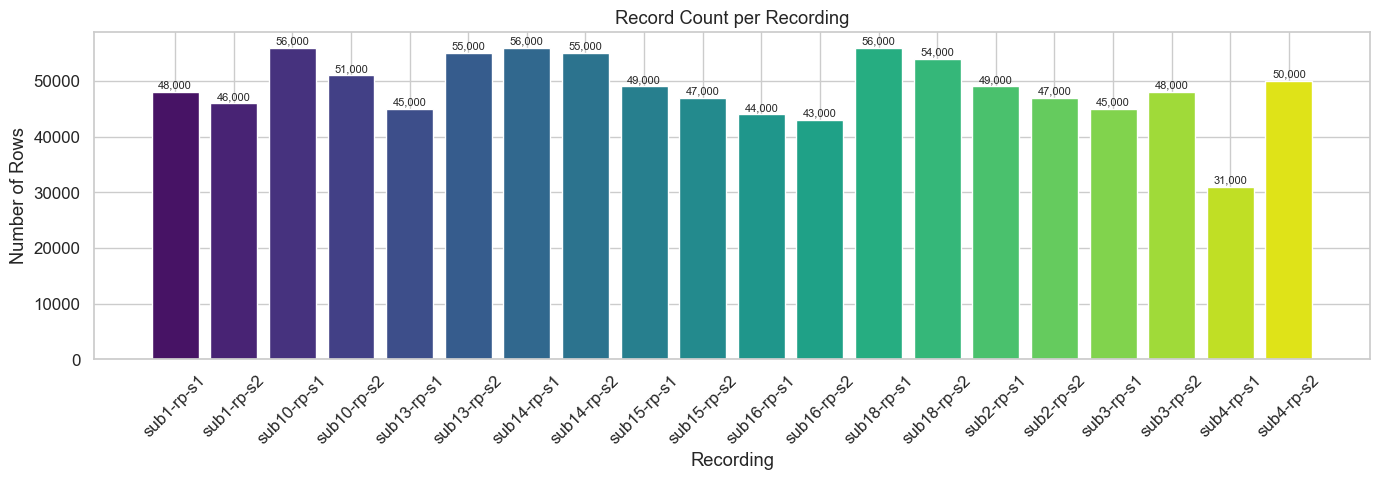

Saved → results/record_counts.png


In [10]:
# 4b. Bar chart of record counts
fig, ax = plt.subplots(figsize=(14, 5))
colors = sns.color_palette("viridis", len(counts_df))
bars = ax.bar(counts_df["recording"], counts_df["total_rows"], color=colors)
ax.set_xlabel("Recording")
ax.set_ylabel("Number of Rows")
ax.set_title("Record Count per Recording")
ax.tick_params(axis="x", rotation=45)
for bar, val in zip(bars, counts_df["total_rows"]):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 300,
            f"{val:,}", ha="center", va="bottom", fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "record_counts.png"), bbox_inches="tight")
plt.show()
print("Saved → results/record_counts.png")

---
## 5 — Data Quality Checks

In [11]:
# 5a. Run data quality checks on every recording
quality_reports = []
for name in sorted(recordings.keys()):
    df = recordings[name]
    report = check_data_quality(df, name)
    quality_reports.append(report)

# Summarise in a table
quality_summary = pd.DataFrame([{
    "recording": r["name"],
    "rows": r["shape"][0],
    "cols": r["shape"][1],
    "missing_total": r["total_missing"],
    "duplicate_rows": r["duplicate_rows"],
    "inf_values": sum(r["inf_values_per_column"].values()),
} for r in quality_reports])

print("Data Quality Summary:\n")
display(quality_summary)

total_missing = quality_summary["missing_total"].sum()
total_dupes = quality_summary["duplicate_rows"].sum()
total_inf = quality_summary["inf_values"].sum()
print(f"\n✅ Total missing values : {total_missing}")
print(f"✅ Total duplicate rows : {total_dupes}")
print(f"✅ Total infinite values: {total_inf}")

Data Quality Summary:



,recording,rows,cols,missing_total,duplicate_rows,inf_values
0,sub1-rp-s1,48000,6,0,0,0
1,sub1-rp-s2,46000,6,0,0,0
2,sub10-rp-s1,56000,6,0,0,0
3,sub10-rp-s2,51000,6,0,0,0
4,sub13-rp-s1,45000,6,0,0,0
5,sub13-rp-s2,55000,6,0,0,0
6,sub14-rp-s1,56000,6,0,0,0
7,sub14-rp-s2,55000,6,0,0,0
8,sub15-rp-s1,49000,6,0,0,0
9,sub15-rp-s2,47000,6,0,0,0



✅ Total missing values : 0
✅ Total duplicate rows : 0
✅ Total infinite values: 0


In [12]:
# 5b. Descriptive statistics for numeric columns (all recordings combined)
all_data = pd.concat(
    [df.assign(recording=name) for name, df in sorted(recordings.items())],
    ignore_index=True
)
print("Descriptive statistics across all recordings (numeric columns):\n")
display(all_data[["X", "Y", "Z"]].describe())

Descriptive statistics across all recordings (numeric columns):



,X,Y,Z
count,975000.000000,975000.000000,975000.000000
mean,-0.101726,-0.798425,-0.064951
std,0.352296,0.678280,0.345609
min,-3.939117,-5.436188,-5.783081
25%,-0.263153,-1.186096,-0.204727
50%,-0.083420,-0.898804,-0.032539
75%,0.096863,-0.606186,0.122787
max,1.910400,3.943924,2.950058


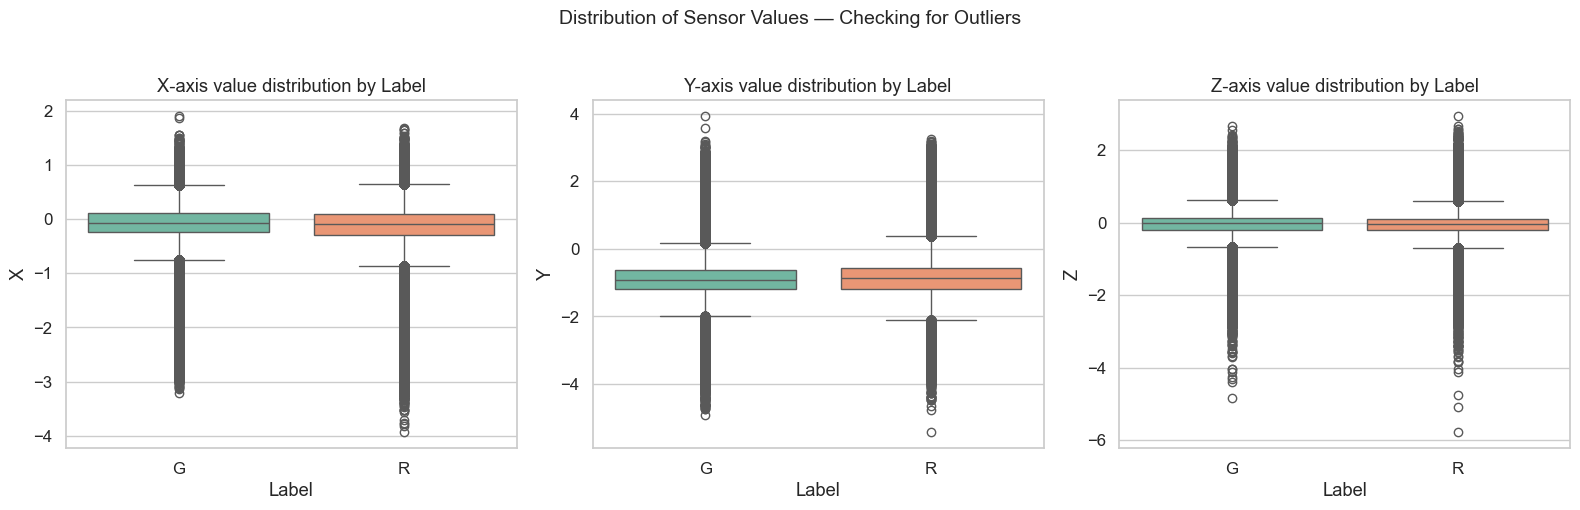

Saved → results/value_distributions_boxplot.png


In [13]:
# 5c. Check for invalid/extreme values using boxplots
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for i, col in enumerate(["X", "Y", "Z"]):
    sns.boxplot(data=all_data, x="Label", y=col, ax=axes[i], palette="Set2")
    axes[i].set_title(f"{col}-axis value distribution by Label")
plt.suptitle("Distribution of Sensor Values — Checking for Outliers", fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "value_distributions_boxplot.png"), bbox_inches="tight")
plt.show()
print("Saved → results/value_distributions_boxplot.png")

---
## 6 — Timestamps & Sampling Frequency

In [14]:
# 6a. Examine raw timestamp values
sample_df = recordings[sorted(recordings.keys())[0]]
print("First 5 timestamps:")
print(sample_df["Timestamp"].head().tolist())
print(f"\nTimestamp range: {sample_df['Timestamp'].min():.6f} → {sample_df['Timestamp'].max():.6f}")
print(f"Duration (raw units): {sample_df['Timestamp'].max() - sample_df['Timestamp'].min():.2f}")

# Compute consecutive differences
diffs = np.diff(sample_df["Timestamp"].values)
print(f"\nTimestamp differences (first 10): {diffs[:10]}")
print(f"Median Δt = {np.median(diffs):.6f}")
print(f"This is ~0.01, suggesting timestamps are in SECONDS.")
print(f"→ Sampling frequency ≈ {1/np.median(diffs[diffs>0]):.1f} Hz")

First 5 timestamps:
[271130.701827875, 271130.711776875, 271130.721755875, 271130.731734875, 271130.741683875]

Timestamp range: 271130.701828 → 271669.051747
Duration (raw units): 538.35

Timestamp differences (first 10): [0.009949 0.009979 0.009979 0.009949 0.009979 0.009979 0.00998  0.009948
 0.00998  0.009979]
Median Δt = 0.009979
This is ~0.01, suggesting timestamps are in SECONDS.
→ Sampling frequency ≈ 100.2 Hz


In [15]:
# 6b. Estimate sampling frequency for every recording
freq_rows = []
for name in sorted(recordings.keys()):
    df = recordings[name]
    info = estimate_sampling_frequency(df)
    freq_rows.append({
        "recording": name,
        "median_dt_sec": info["median_dt"],
        "mean_dt_sec": info["mean_dt"],
        "std_dt_sec": info["std_dt"],
        "min_dt_sec": info["min_dt"],
        "max_dt_sec": info["max_dt"],
        "est_freq_hz": info["estimated_freq_hz"],
    })

freq_df = pd.DataFrame(freq_rows)
print("Sampling frequency estimates:\n")
display(freq_df)

print(f"\nOverall estimated sampling frequency: ~{freq_df['est_freq_hz'].median():.0f} Hz")
print("All recordings are sampled at approximately 100 Hz (100 samples per second).")

Sampling frequency estimates:



,recording,median_dt_sec,mean_dt_sec,std_dt_sec,min_dt_sec,max_dt_sec,est_freq_hz
0,sub1-rp-s1,0.009979,0.011216,0.272980,0.009900,59.816851,100.210442
1,sub1-rp-s2,0.009979,0.010648,0.139757,0.009919,29.982353,100.210442
2,sub10-rp-s1,0.009979,0.009964,0.000015,0.009900,0.009989,100.210442
3,sub10-rp-s2,0.009979,0.010561,0.132477,0.009901,29.927386,100.210442
4,sub13-rp-s1,0.009979,0.010652,0.141222,0.009919,29.967728,100.210442
5,sub13-rp-s2,0.009979,0.011067,0.180629,0.009903,29.972673,100.210442
6,sub14-rp-s1,0.009979,0.010500,0.126345,0.009903,29.908576,100.210442
7,sub14-rp-s2,0.009979,0.010531,0.127747,0.009907,29.969394,100.210442
8,sub15-rp-s1,0.009979,0.010581,0.135118,0.009902,29.919527,100.210442
9,sub15-rp-s2,0.009979,0.010623,0.138235,0.009910,29.978605,100.210442



Overall estimated sampling frequency: ~100 Hz
All recordings are sampled at approximately 100 Hz (100 samples per second).


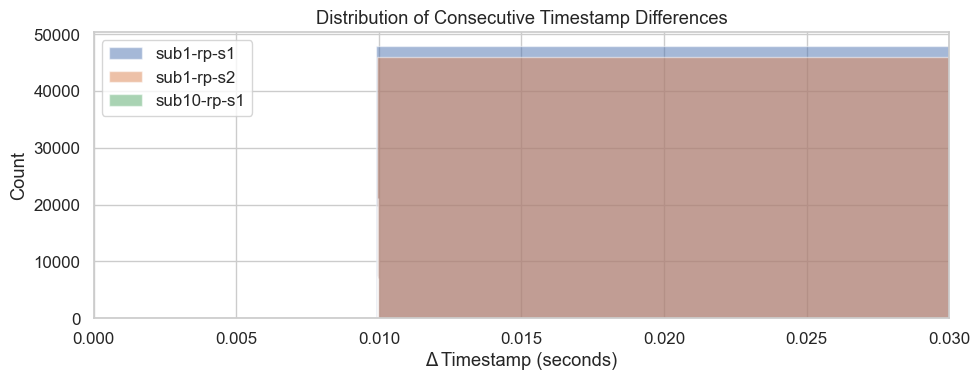

Saved → results/timestamp_diffs_histogram.png


In [16]:
# 6c. Histogram of timestamp differences (should peak near 0.01 sec)
fig, ax = plt.subplots(figsize=(10, 4))
# Use the first 3 recordings for the histogram
for name in sorted(recordings.keys())[:3]:
    diffs = np.diff(recordings[name]["Timestamp"].values)
    ax.hist(diffs[diffs > 0], bins=100, alpha=0.5, label=name)
ax.set_xlabel("Δ Timestamp (seconds)")
ax.set_ylabel("Count")
ax.set_title("Distribution of Consecutive Timestamp Differences")
ax.legend()
ax.set_xlim(0, 0.03)  # zoom in on the main peak
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "timestamp_diffs_histogram.png"), bbox_inches="tight")
plt.show()
print("Saved → results/timestamp_diffs_histogram.png")

In [17]:
# 6d. Check for timestamp anomalies (large gaps, backwards jumps)
print("Timestamp anomaly check:\n")
for name in sorted(recordings.keys()):
    df = recordings[name]
    diffs = np.diff(df["Timestamp"].values)
    negative = (diffs < 0).sum()
    zero = (diffs == 0).sum()
    # Large gaps = more than 10× the median Δt
    median_dt = np.median(diffs[diffs > 0])
    large_gaps = (diffs > 10 * median_dt).sum()
    flag = "⚠️" if (negative > 0 or large_gaps > 0) else "✅"
    print(f"  {flag} {name}: negative={negative}, zero={zero}, large_gaps={large_gaps}")

print("\nNote: The G and R samples are interleaved, so when looking at ONLY")
print("one label the timestamps may show small 'gaps' — this is expected.")

Timestamp anomaly check:

  ⚠️ sub1-rp-s1: negative=0, zero=0, large_gaps=1
  ⚠️ sub1-rp-s2: negative=0, zero=0, large_gaps=2
  ✅ sub10-rp-s1: negative=0, zero=0, large_gaps=0
  ⚠️ sub10-rp-s2: negative=0, zero=0, large_gaps=1
  ⚠️ sub13-rp-s1: negative=0, zero=0, large_gaps=1
  ⚠️ sub13-rp-s2: negative=0, zero=0, large_gaps=2
  ⚠️ sub14-rp-s1: negative=0, zero=0, large_gaps=1
  ⚠️ sub14-rp-s2: negative=0, zero=0, large_gaps=1
  ⚠️ sub15-rp-s1: negative=0, zero=0, large_gaps=1
  ⚠️ sub15-rp-s2: negative=0, zero=0, large_gaps=1
  ⚠️ sub16-rp-s1: negative=0, zero=0, large_gaps=1
  ⚠️ sub16-rp-s2: negative=0, zero=0, large_gaps=1
  ⚠️ sub18-rp-s1: negative=0, zero=0, large_gaps=1
  ⚠️ sub18-rp-s2: negative=0, zero=0, large_gaps=1
  ⚠️ sub2-rp-s1: negative=0, zero=0, large_gaps=1
  ⚠️ sub2-rp-s2: negative=0, zero=0, large_gaps=1
  ⚠️ sub3-rp-s1: negative=0, zero=0, large_gaps=3
  ⚠️ sub3-rp-s2: negative=0, zero=0, large_gaps=1
  ✅ sub4-rp-s1: negative=0, zero=0, large_gaps=0
  ⚠️ sub4-rp-s

---
## 7 — Sensor Signal Visualisation

In [18]:
# 7a. Helper function to plot X/Y/Z signals for one recording
def plot_sensor_signals(df, title, save_name=None, n_samples=2000):
    """
    Plot the first n_samples of X, Y, Z sensor data.
    Separate subplots for each label (G / R) if both are present.
    """
    labels_present = df["Label"].unique()
    n_labels = len(labels_present)
    
    fig, axes = plt.subplots(n_labels, 1, figsize=(14, 4 * n_labels), sharex=False)
    if n_labels == 1:
        axes = [axes]
    
    colors = {"X": "#e74c3c", "Y": "#2ecc71", "Z": "#3498db"}
    
    for ax, label in zip(axes, sorted(labels_present)):
        subset = df[df["Label"] == label].head(n_samples)
        time = subset["Timestamp"] - subset["Timestamp"].iloc[0]  # start from 0
        
        for axis in ["X", "Y", "Z"]:
            ax.plot(time, subset[axis], label=axis, color=colors[axis],
                    linewidth=0.7, alpha=0.85)
        
        label_name = "Gyroscope" if label == "G" else "Rotation/Accel"
        ax.set_title(f"{title} — {label_name} ({label})")
        ax.set_ylabel("Sensor Value")
        ax.legend(loc="upper right")
        ax.set_xlabel("Time (seconds from start)")
    
    plt.tight_layout()
    if save_name:
        plt.savefig(os.path.join(RESULTS_DIR, save_name), bbox_inches="tight")
    plt.show()

print("Plotting function defined ✓")

Plotting function defined ✓


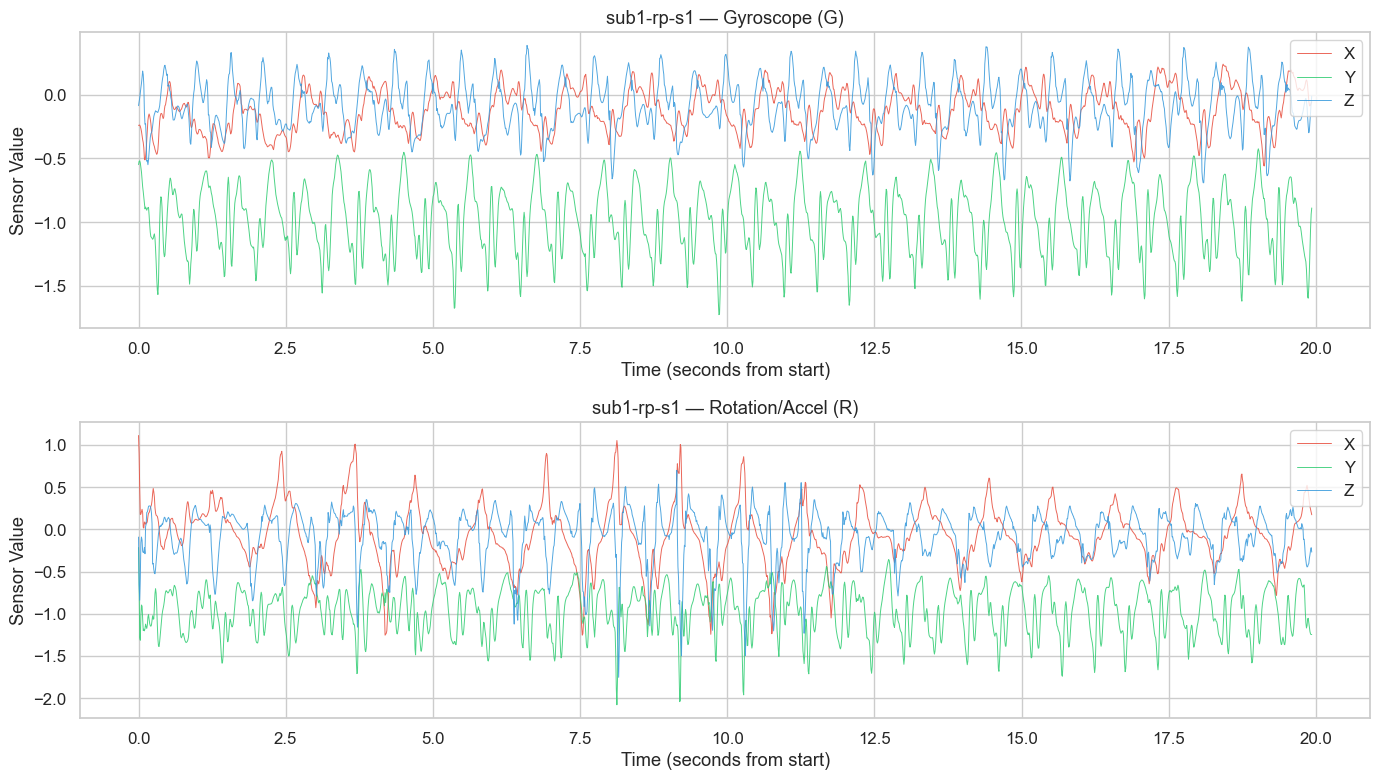

Saved → results/signals_sub1-rp-s1.png



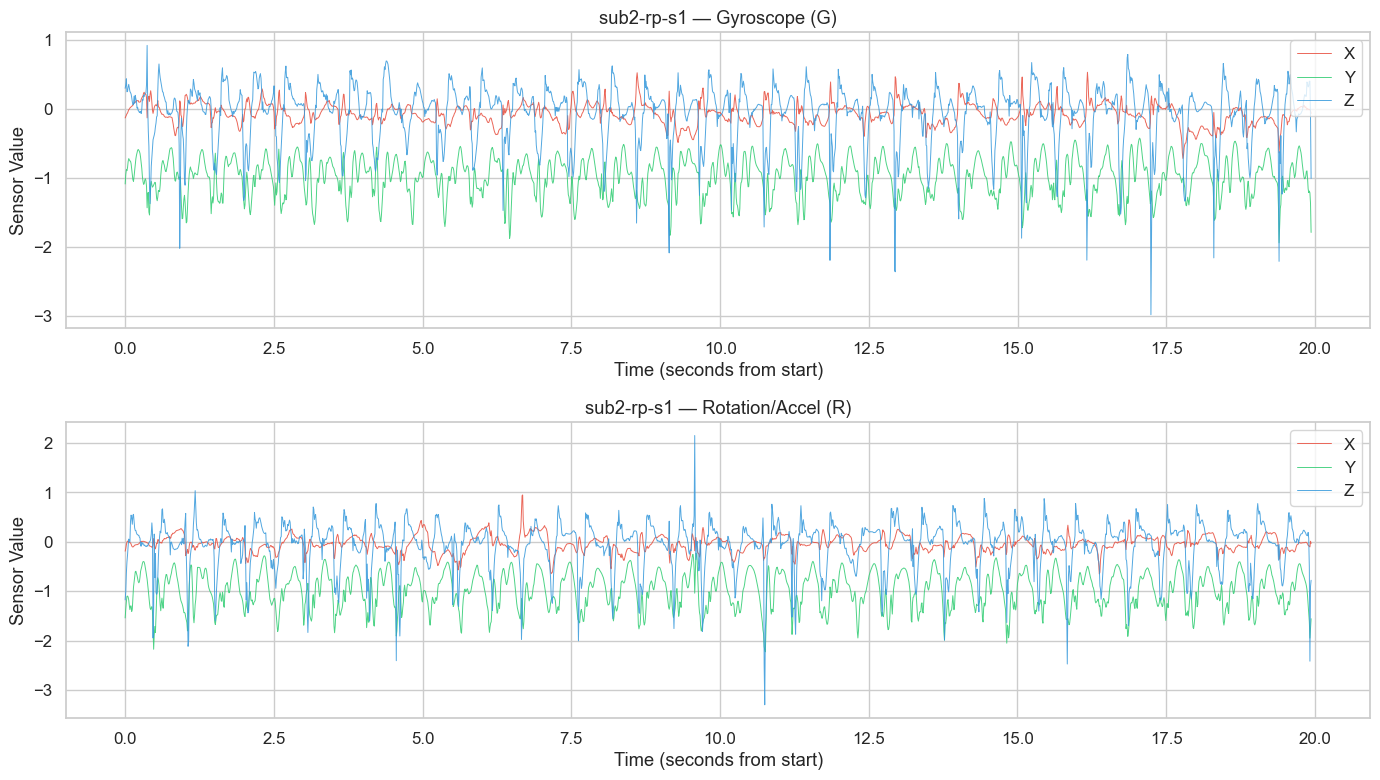

Saved → results/signals_sub2-rp-s1.png



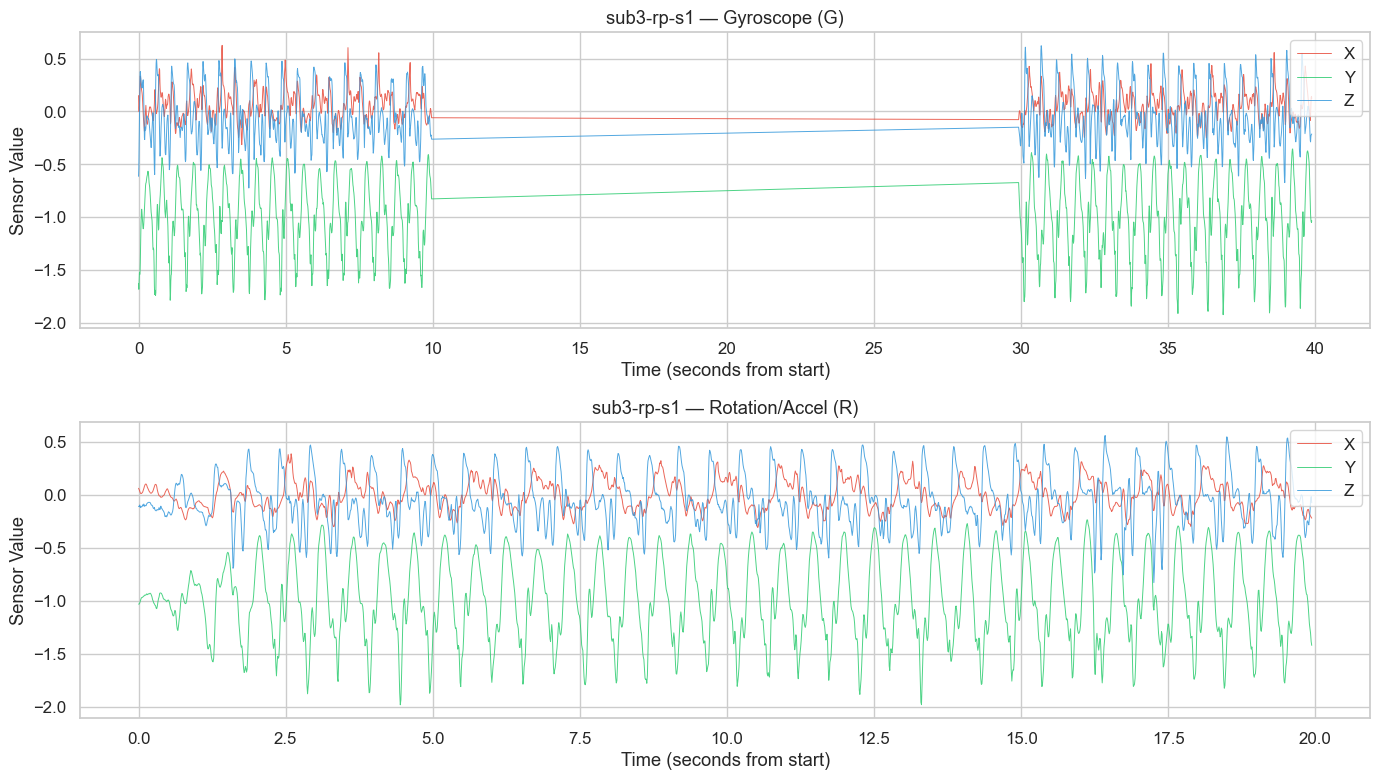

Saved → results/signals_sub3-rp-s1.png



In [19]:
# 7b. Plot signals for the first 3 participants (session 1)
plot_recordings = ["sub1-rp-s1", "sub2-rp-s1", "sub3-rp-s1"]
for rec_name in plot_recordings:
    if rec_name in recordings:
        plot_sensor_signals(
            recordings[rec_name],
            title=rec_name,
            save_name=f"signals_{rec_name}.png",
            n_samples=2000
        )
        print(f"Saved → results/signals_{rec_name}.png\n")

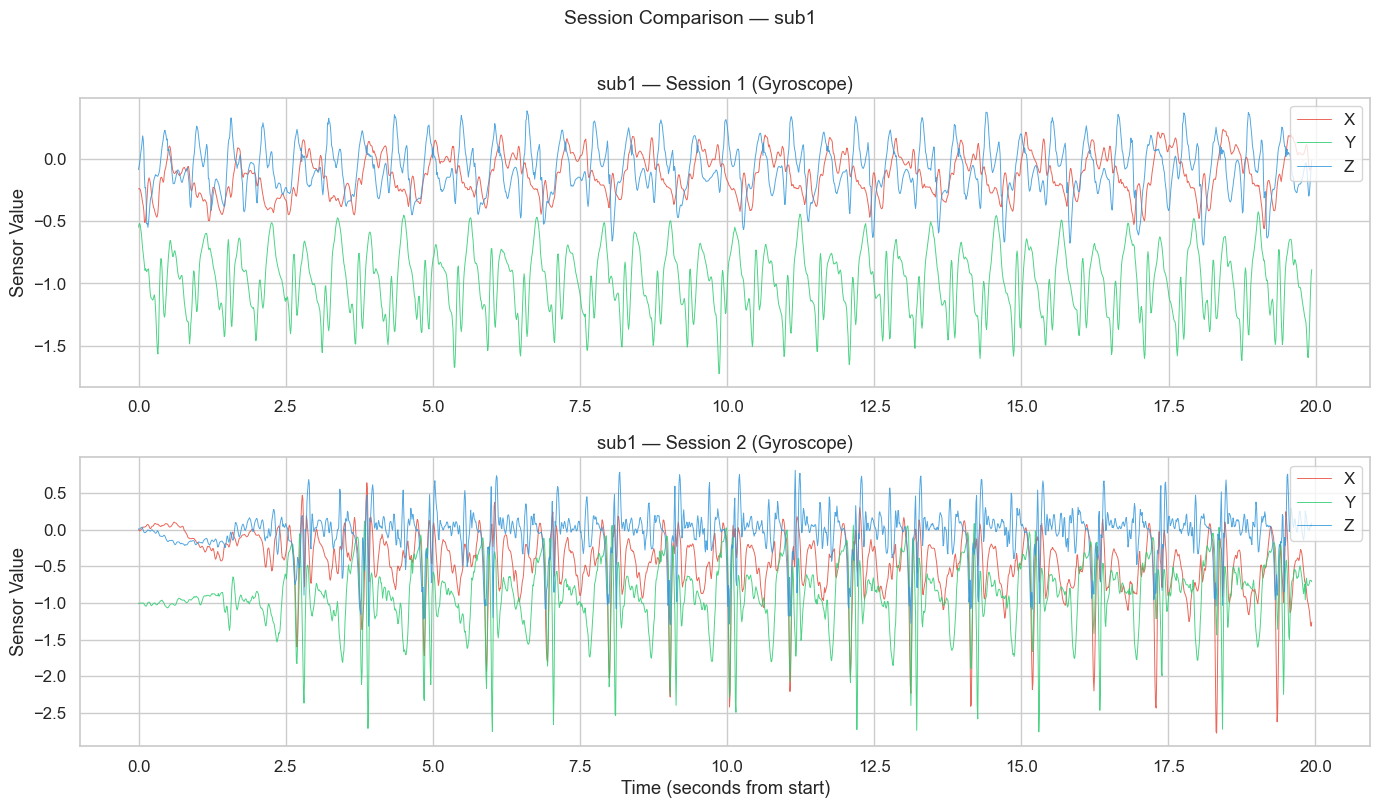

Saved → results/session_comparison_sub1.png


In [20]:
# 7c. Compare Session 1 vs Session 2 for one participant
participant = "sub1"
s1_name = f"{participant}-rp-s1"
s2_name = f"{participant}-rp-s2"

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=False)
colors = {"X": "#e74c3c", "Y": "#2ecc71", "Z": "#3498db"}

for ax, sess_name, sess_label in zip(axes, [s1_name, s2_name], ["Session 1", "Session 2"]):
    df = recordings[sess_name]
    # Plot only Gyroscope data for clarity
    g_data = df[df["Label"] == "G"].head(2000)
    time = g_data["Timestamp"] - g_data["Timestamp"].iloc[0]
    for axis in ["X", "Y", "Z"]:
        ax.plot(time, g_data[axis], label=axis, color=colors[axis],
                linewidth=0.7, alpha=0.85)
    ax.set_title(f"{participant} — {sess_label} (Gyroscope)")
    ax.set_ylabel("Sensor Value")
    ax.legend(loc="upper right")

axes[-1].set_xlabel("Time (seconds from start)")
plt.suptitle(f"Session Comparison — {participant}", fontsize=14, y=1.01)
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, f"session_comparison_{participant}.png"), bbox_inches="tight")
plt.show()
print(f"Saved → results/session_comparison_{participant}.png")

---
## 8 — Participant & Session Comparison

In [21]:
# 8a. Compute per-recording statistics for G-labeled data
import re

stat_rows = []
for name in sorted(recordings.keys()):
    df = recordings[name]
    m = re.search(r"sub(\d+)-rp-s(\d+)", name)
    pid = int(m.group(1))
    sess = int(m.group(2))

    for label in df["Label"].unique():
        subset = df[df["Label"] == label]
        stat_rows.append({
            "participant": pid,
            "session": sess,
            "label": label,
            "count": len(subset),
            "X_mean": subset["X"].mean(),
            "X_std": subset["X"].std(),
            "Y_mean": subset["Y"].mean(),
            "Y_std": subset["Y"].std(),
            "Z_mean": subset["Z"].mean(),
            "Z_std": subset["Z"].std(),
            "magnitude_mean": np.sqrt(subset["X"]**2 + subset["Y"]**2 + subset["Z"]**2).mean(),
        })

stats_df = pd.DataFrame(stat_rows)
print("Per-recording statistics (G = Gyroscope, R = Rotation/Accel):\n")
display(stats_df.round(4))

Per-recording statistics (G = Gyroscope, R = Rotation/Accel):



,participant,session,label,count,X_mean,X_std,Y_mean,Y_std,Z_mean,Z_std,magnitude_mean
0,1,1,G,24000,-0.0676,0.3320,-0.9785,0.2774,-0.0476,0.3184,1.0704
1,1,1,R,24000,-0.0426,0.3215,-0.9780,0.2883,-0.0809,0.2854,1.0636
2,1,2,G,23000,-0.6683,0.4886,-0.7612,0.4406,-0.0209,0.2931,1.1105
3,1,2,R,23000,-0.6851,0.5030,-0.7546,0.4304,-0.0220,0.2744,1.1090
4,10,1,G,56000,0.0198,0.1961,-1.0160,0.2197,-0.0074,0.3411,1.0724
5,10,2,G,25000,-0.2237,0.1807,-0.9315,0.2532,-0.2478,0.2472,1.0329
6,10,2,R,26000,-0.3318,0.1850,-0.8958,0.2306,-0.2559,0.2308,1.0298
7,13,1,G,22000,-0.1884,0.2166,0.9472,0.5233,-0.1587,0.3409,1.0695
8,13,1,R,23000,-0.1877,0.2458,0.9506,0.4998,-0.1574,0.3359,1.0698
9,13,2,G,27000,0.1632,0.1813,-0.9602,0.3780,-0.1830,0.3440,1.0655


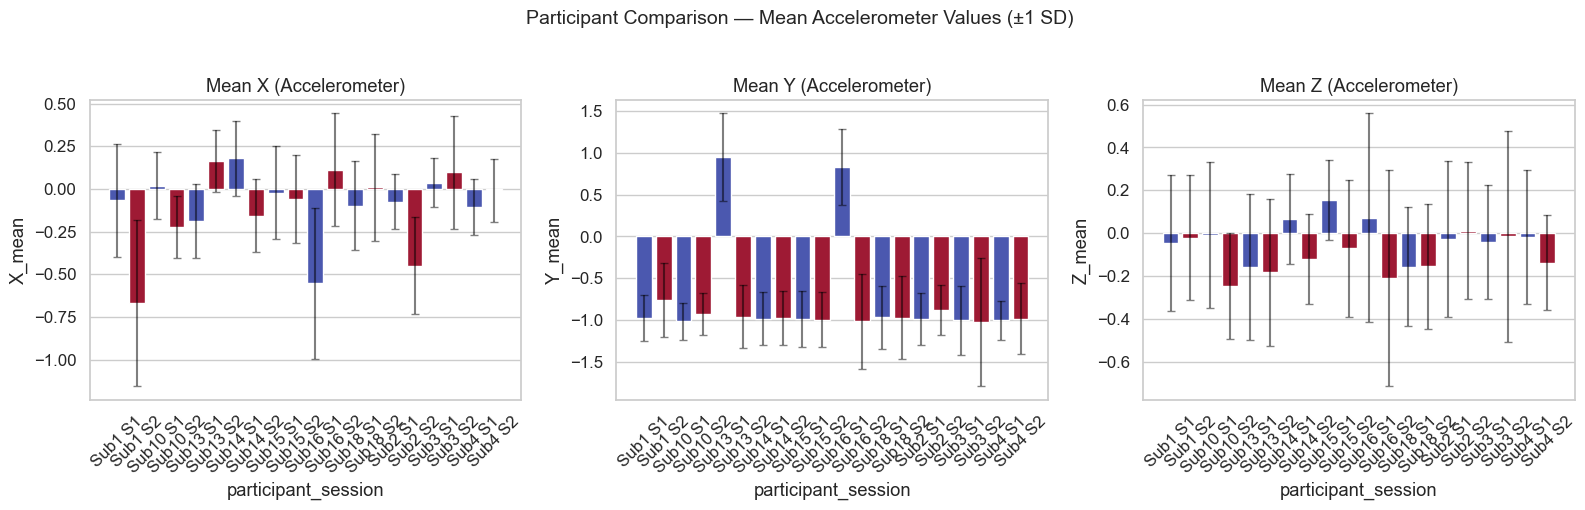

Saved → results/participant_comparison_accelerometer_means.png


In [22]:
# 8b. Visualise mean signal magnitude per participant (Accelerometer only)
g_stats = stats_df[stats_df["label"] == "G"].copy()
g_stats["participant_session"] = (
    "Sub" + g_stats["participant"].astype(str) + " S" + g_stats["session"].astype(str)
)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for i, axis in enumerate(["X", "Y", "Z"]):
    ax = axes[i]
    sns.barplot(
        data=g_stats, x="participant_session", y=f"{axis}_mean",
        hue="session", dodge=False, ax=ax, palette="coolwarm"
    )
    # Add error bars for std
    ax.errorbar(
        range(len(g_stats)), g_stats[f"{axis}_mean"],
        yerr=g_stats[f"{axis}_std"], fmt="none", c="black", capsize=3, alpha=0.5
    )
    ax.set_title(f"Mean {axis} (Accelerometer)")
    ax.tick_params(axis="x", rotation=45)
    ax.get_legend().remove()

plt.suptitle("Participant Comparison — Mean Accelerometer Values (±1 SD)", fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "participant_comparison_accelerometer_means.png"), bbox_inches="tight")
plt.show()
print("Saved → results/participant_comparison_accelerometer_means.png")

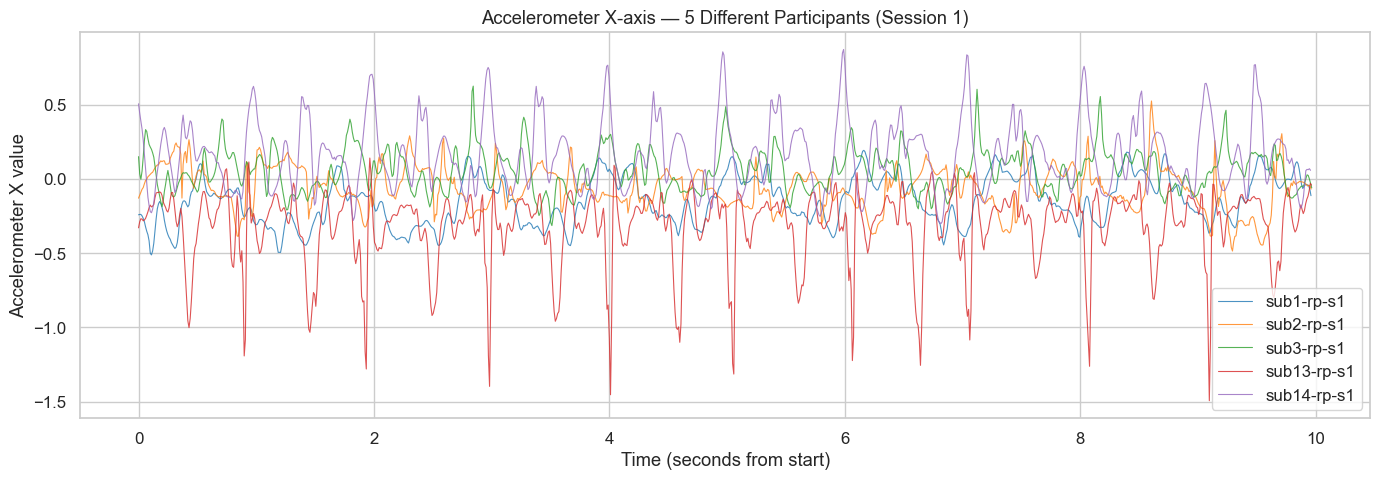

Saved → results/multi_participant_accelerometer_X.png


In [23]:
# 8c. Overlay Accelerometer X-axis for multiple participants to show gait differences
fig, ax = plt.subplots(figsize=(14, 5))
palette = sns.color_palette("tab10", 5)
participants_to_compare = ["sub1-rp-s1", "sub2-rp-s1", "sub3-rp-s1", "sub13-rp-s1", "sub14-rp-s1"]

for i, rec_name in enumerate(participants_to_compare):
    if rec_name not in recordings:
        continue
    df = recordings[rec_name]
    g_data = df[df["Label"] == "G"].head(1000)
    time = g_data["Timestamp"] - g_data["Timestamp"].iloc[0]
    ax.plot(time, g_data["X"], label=rec_name, color=palette[i],
            linewidth=0.8, alpha=0.8)

ax.set_xlabel("Time (seconds from start)")
ax.set_ylabel("Accelerometer X value")
ax.set_title("Accelerometer X-axis — 5 Different Participants (Session 1)")
ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "multi_participant_accelerometer_X.png"), bbox_inches="tight")
plt.show()
print("Saved → results/multi_participant_accelerometer_X.png")

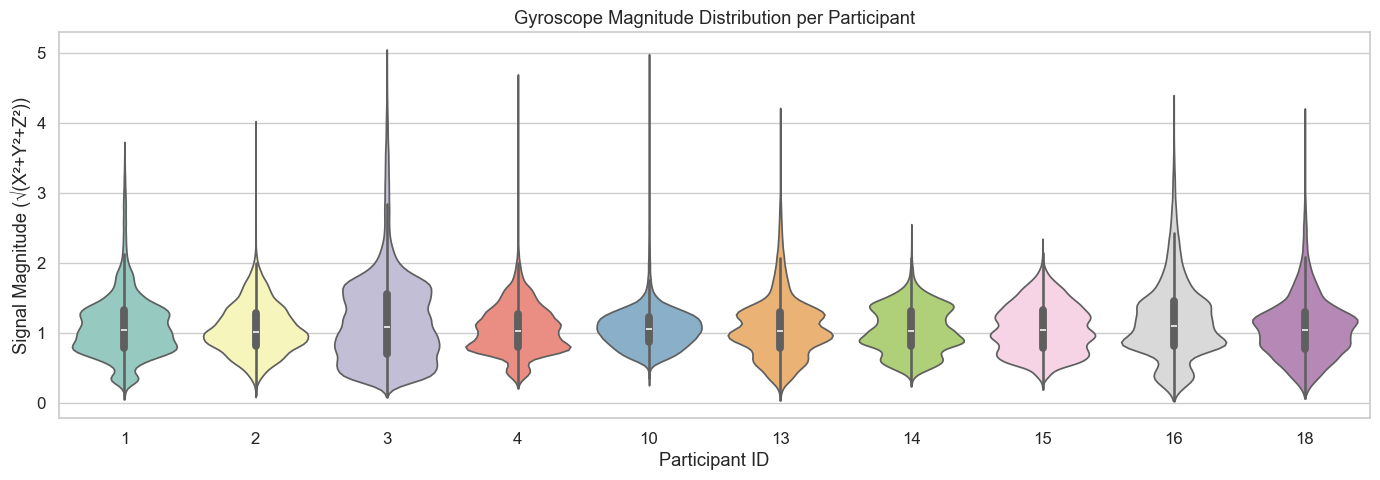

Saved → results/magnitude_violin_per_participant.png


In [24]:
# 8d. Signal magnitude distribution — violin plot per participant
# Use gyroscope data only
g_all = all_data[all_data["Label"] == "G"].copy()
g_all["magnitude"] = np.sqrt(g_all["X"]**2 + g_all["Y"]**2 + g_all["Z"]**2)

# Extract participant ID from 'recording' column
g_all["participant"] = g_all["recording"].str.extract(r"sub(\d+)").astype(int)

fig, ax = plt.subplots(figsize=(14, 5))
sns.violinplot(
    data=g_all, x="participant", y="magnitude", hue="participant",
    palette="Set3", inner="box", cut=0, ax=ax, legend=False
)
ax.set_xlabel("Participant ID")
ax.set_ylabel("Signal Magnitude (√(X²+Y²+Z²))")
ax.set_title("Gyroscope Magnitude Distribution per Participant")
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "magnitude_violin_per_participant.png"), bbox_inches="tight")
plt.show()
print("Saved → results/magnitude_violin_per_participant.png")

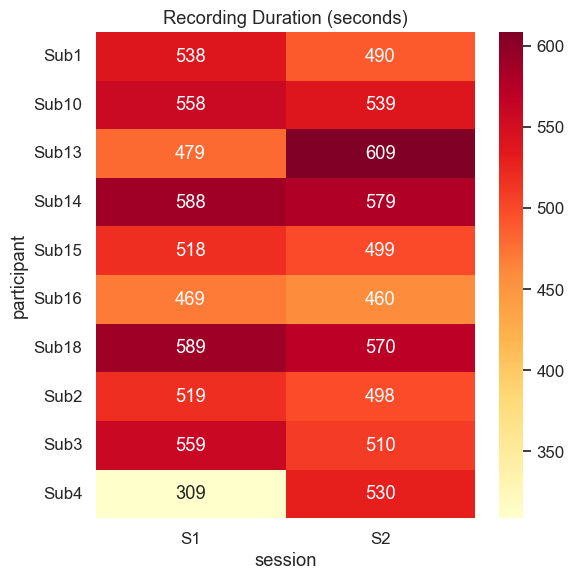

Saved → results/duration_heatmap.png


In [25]:
# 8e. Heatmap of recording durations (seconds)
duration_rows = []
for name in sorted(recordings.keys()):
    df = recordings[name]
    m = re.search(r"sub(\d+)-rp-s(\d+)", name)
    pid = int(m.group(1))
    sess = int(m.group(2))
    duration_sec = df["Timestamp"].max() - df["Timestamp"].min()
    duration_rows.append({"participant": f"Sub{pid}", "session": f"S{sess}",
                          "duration_sec": duration_sec})

dur_df = pd.DataFrame(duration_rows)
dur_pivot = dur_df.pivot(index="participant", columns="session", values="duration_sec")

fig, ax = plt.subplots(figsize=(6, 6))
sns.heatmap(dur_pivot, annot=True, fmt=".0f", cmap="YlOrRd", ax=ax)
ax.set_title("Recording Duration (seconds)")
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "duration_heatmap.png"), bbox_inches="tight")
plt.show()
print("Saved → results/duration_heatmap.png")

---
## 9 — Summary of Findings

### Dataset at a glance

| Property | Value |
|---|---|
| Source | 200GaitData (smartphone-based gait recordings) |
| Files | 20 CSV files |
| Participants | 10 (IDs: 1, 2, 3, 4, 10, 13, 14, 15, 16, 18) |
| Sessions per participant | 2 |
| Columns | OriginalIndex, Timestamp, X, Y, Z, Label |
| Labels | G (Gyroscope), R (Rotation/Accelerometer) |
| Sampling frequency | ~100 Hz |
| Missing values | 0 |
| Duplicate rows | 0 |
| Rows per file | 31,000 – 56,000 |

### Key observations

1. **Clean data:** No missing values, no duplicates, no infinite values.
2. **Two sensor types** are interleaved in each file (G = Gyroscope, R = Rotation/Accel). Some files contain only G samples.
3. **Consistent sampling:** ~100 Hz across all recordings, with very low jitter.
4. **Gait patterns differ** visibly between participants — this is exactly what biometric authentication relies on.
5. **Session-to-session variation** exists for the same participant — the adaptive template updating will need to handle this.
6. **File naming quirks:** leading spaces and double `.csv.csv` extensions — handled by our data loader.

### Ready for Phase 2

The dataset is clean and well-structured. Next steps:
- Separate G and R sensor streams
- Segment signals into individual gait cycles
- Implement DTW-based template matching
- Build the authentication pipeline

In [26]:
# Save the quality and frequency summary tables as CSV for reference
quality_summary.to_csv(os.path.join(RESULTS_DIR, "data_quality_summary.csv"), index=False)
freq_df.to_csv(os.path.join(RESULTS_DIR, "sampling_frequency_summary.csv"), index=False)
stats_df.to_csv(os.path.join(RESULTS_DIR, "per_recording_statistics.csv"), index=False)
counts_df.to_csv(os.path.join(RESULTS_DIR, "record_counts.csv"), index=False)

print("Saved summary tables to results/:")
for f in sorted(os.listdir(RESULTS_DIR)):
    print(f"  📄 {f}")

print("\n🎉 Phase 1 — Dataset Exploration complete!")

Saved summary tables to results/:
  📄 data_quality_summary.csv
  📄 duration_heatmap.png
  📄 magnitude_violin_per_participant.png
  📄 multi_participant_accelerometer_X.png
  📄 participant_comparison_accelerometer_means.png
  📄 per_recording_statistics.csv
  📄 record_counts.csv
  📄 record_counts.png
  📄 sampling_frequency_summary.csv
  📄 session_comparison_sub1.png
  📄 signals_sub1-rp-s1.png
  📄 signals_sub2-rp-s1.png
  📄 signals_sub3-rp-s1.png
  📄 timestamp_diffs_histogram.png
  📄 value_distributions_boxplot.png

🎉 Phase 1 — Dataset Exploration complete!
